**Segmentasi Citra Berbasis Similaritas**

---

### 1. Konsep Segmentasi Berbasis Similaritas

Segmentasi berbasis similaritas mengelompokkan piksel-piksel yang memiliki kesamaan nilai intensitas, tekstur, atau atribut lainnya. Pendekatan ini berfokus pada keseragaman lokal atau global dalam citra untuk memisahkan objek dari latar belakang.

Metode populer:

* *Global Thresholding*
* *Otsu’s Method*
* *Optimal Thresholding Iteratif*
* *Adaptive Thresholding*
* *Histogram of Gradient (HoG)*

---

### 2. Global Thresholding

#### Konsep:

Global thresholding membagi piksel menjadi dua kelompok (foreground/objek dan background/latar belakang) berdasarkan nilai ambang (threshold) tetap.

#### Implementasi:

```python
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('image.jpg', 0)
_, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

plt.imshow(thresh, cmap='gray')
plt.title('Global Thresholding')
plt.axis('off')
plt.show()
```

#### Eksperimen:

```python
for t in [50, 100, 150, 200]:
    _, th = cv2.threshold(img, t, 255, cv2.THRESH_BINARY)
    plt.figure(), plt.imshow(th, cmap='gray')
    plt.title(f'Threshold: {t}'), plt.axis('off')
```

---

### 3. Otsu’s Method

#### Konsep:

Otsu mencari ambang optimal dengan meminimalkan variansi intra-kelas.

#### Implementasi:

```python
_, otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
plt.imshow(otsu, cmap='gray')
plt.title('Otsu Thresholding')
plt.axis('off')
plt.show()
```

#### Visualisasi Histogram:

```python
plt.hist(img.ravel(), bins=256, range=[0,256])
plt.axvline(_, color='r', label=f'Threshold: {_:.2f}')
plt.title('Histogram dan Threshold Otsu')
plt.legend()
plt.show()
```

---

### 4. Optimal Thresholding (Iteratif)

#### Konsep:

1. Tentukan threshold awal (misal rata-rata intensitas)
2. Kelompokkan piksel menjadi dua berdasarkan threshold
3. Hitung rata-rata masing-masing kelompok
4. Update threshold sebagai rata-rata dari dua nilai rata-rata tersebut
5. Ulangi hingga konvergen

#### Implementasi:

```python
def optimal_threshold(img):
    T = img.mean()
    while True:
        G1 = img[img > T]
        G2 = img[img <= T]
        new_T = (G1.mean() + G2.mean()) / 2
        if abs(T - new_T) < 1:
            break
        T = new_T
    return T

T = optimal_threshold(img)
ret, opt_thresh = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)
plt.imshow(opt_thresh, cmap='gray')
plt.title(f'Optimal Threshold = {T:.2f}')
plt.axis('off')
plt.show()
```

---

### 5. Adaptive Thresholding

#### Konsep:

* Menentukan threshold untuk tiap piksel berdasarkan lingkungan lokal (blok kecil).
* Menggunakan ambang lokal berdasarkan rata-rata atau Gaussian dari lingkungan sekitar setiap piksel.

#### Implementasi:

```python
adaptive = cv2.adaptiveThreshold(img, 255,
                                 cv2.ADAPTIVE_THRESH_MEAN_C,
                                 cv2.THRESH_BINARY, 11, 2)
plt.imshow(adaptive, cmap='gray')
plt.title('Adaptive Thresholding')
plt.axis('off')
plt.show()
```

#### Eksperimen Blok Ukuran:

```python
for block_size in [11, 15, 25]:
    adaptive = cv2.adaptiveThreshold(img, 255,
                                     cv2.ADAPTIVE_THRESH_MEAN_C,
                                     cv2.THRESH_BINARY, block_size, 2)
    plt.figure(), plt.imshow(adaptive, cmap='gray')
    plt.title(f'Block size: {block_size}')
```

---

### 6. Histogram of Oriented Gradient (HoG)

#### Konsep:

* Ekstraksi fitur tepi dan orientasi gradien pada blok-blok kecil citra (lokal).
* Digunakan untuk deteksi objek dan segmentasi berbasis fitur.

#### Implementasi (Visualisasi HoG):

```python
from skimage.feature import hog
from skimage import exposure

# Hitung HOG
fd, hog_image = hog(img, orientations=9, pixels_per_cell=(8, 8),
                    cells_per_block=(2, 2), visualize=True)

plt.imshow(hog_image, cmap='gray')
plt.title('Histogram of Gradient - Feature Image')
plt.axis('off')
plt.show()
```

#### Eksperimen:

```python
# Hitung HOG
fd, hog_image = hog(img, orientations=8, pixels_per_cell=(16, 16),
                    cells_per_block=(1, 1), visualize=True)

# Rescale HOG untuk visualisasi
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(122), plt.imshow(hog_image_rescaled, cmap='gray'), plt.title('HOG')
plt.show()
```

---

### 7. Integrasi dengan Penyambungan Tepi

Thresholding dapat dikombinasikan dengan penyambungan tepi untuk menyaring hasil tepi:

```python
edges = cv2.Canny(img, 100, 200)
masked = cv2.bitwise_and(edges, edges, mask=thresh)
plt.imshow(masked, cmap='gray')
plt.title('Tepi setelah Thresholding')
plt.axis('off')
plt.show()
```

---

### 8. Kesimpulan

* Segmentasi berbasis similaritas efektif untuk memisahkan objek dengan intensitas homogen.
* Global thresholding cepat namun tidak fleksibel, cocok untuk citra dengan kontras tinggi.
* Metode Otsu, optimal thresholding, dan adaptive thresholding memberikan hasil otomatis, sehingga lebih fleksibel untuk kondisi pencahayaan tidak merata.
* HoG membuka jalan menuju segmentasi berbasis pembelajaran fitur (feature-based segmentation).
* Eksperimen parameter seperti ambang batas dan ukuran blok menunjukkan sensitivitas metode terhadap variasi input.
* Integrasi dengan metode seperti deteksi tepi dapat meningkatkan kualitas segmentasi akhir.

In [1]:
# Implementasi dan Eksperimen
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure
from skimage.filters import threshold_multiotsu
import time

def show_grid(images, titles, cols=4, size=3.2, cmap='gray', suptitle=None):
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=(size * cols, size * rows))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im, cmap=None if im.ndim == 3 else cmap)
        plt.title(t, fontsize=9)
        plt.axis('off')
    if suptitle:
        plt.suptitle(suptitle, fontsize=12)
    plt.tight_layout()
    plt.show()

def fg_ratio(mask):
    return 100.0 * np.count_nonzero(mask) / mask.size

Ukuran citra : (268, 276)
Intensitas   : min = 32 | max = 202 | mean = 170.64 | std = 26.96

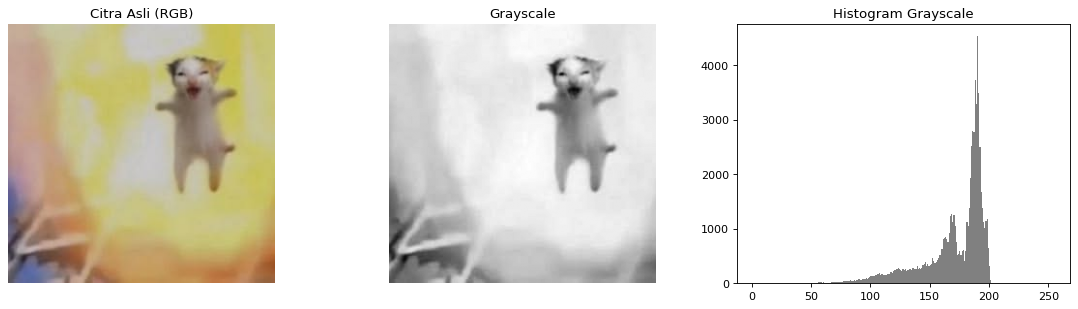

In [2]:
img_color = cv2.imread('explode.jpg')
img_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
img = cv2.imread('explode.jpg', 0)
print('Ukuran citra :', img.shape)
print('Intensitas   : min =', img.min(), '| max =', img.max(), '| mean = %.2f' % img.mean(), '| std = %.2f' % img.std())

plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1), plt.imshow(img_rgb), plt.title('Citra Asli (RGB)'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(img, cmap='gray'), plt.title('Grayscale'), plt.axis('off')
plt.subplot(1, 3, 3), plt.hist(img.ravel(), bins=256, range=[0, 256], color='gray'), plt.title('Histogram Grayscale')
plt.tight_layout()
plt.show()

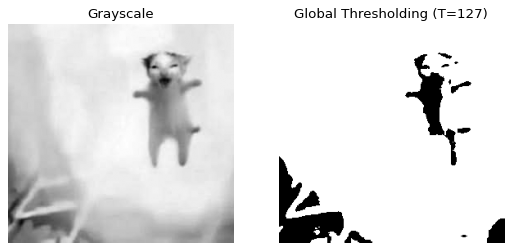

Persentase piksel foreground: 90.35%

In [3]:
# A. Global Thresholding
# A.1 Implementasi dasar (T = 127)
_, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Grayscale'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(thresh, cmap='gray'), plt.title('Global Thresholding (T=127)'), plt.axis('off')
plt.show()
print('Persentase piksel foreground: %.2f%%' % fg_ratio(thresh))

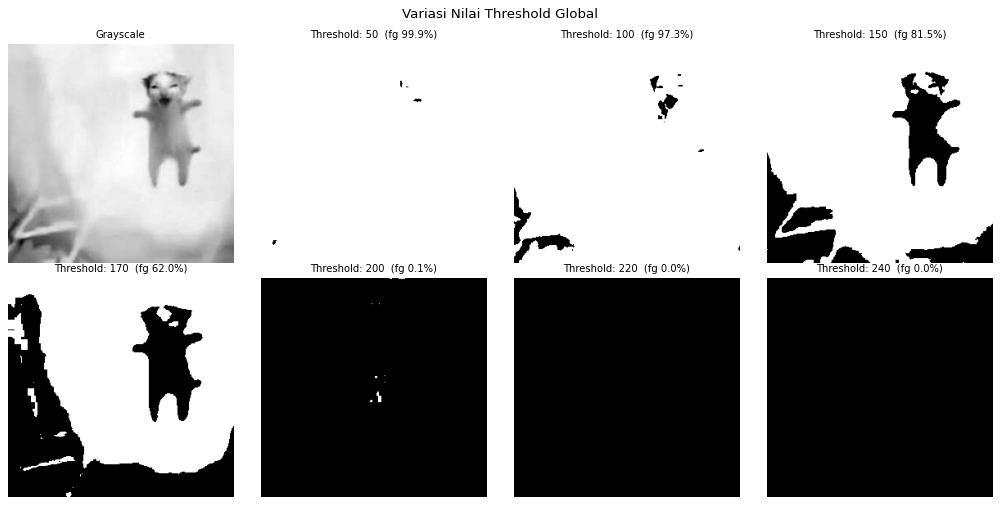

In [4]:
# A.2 Eksperimen variasi nilai threshold
t_values = [50, 100, 150, 170, 200, 220, 240]
ims, tts = [img], ['Grayscale']
for t in t_values:
    _, th = cv2.threshold(img, t, 255, cv2.THRESH_BINARY)
    ims.append(th)
    tts.append(f'Threshold: {t}  (fg {fg_ratio(th):.1f}%)')
show_grid(ims, tts, cols=4, suptitle='Variasi Nilai Threshold Global')

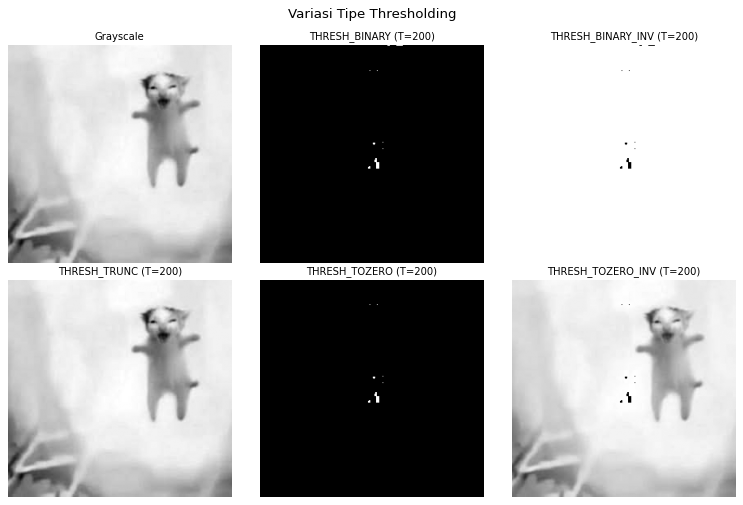

In [5]:
# A.3 Eksperimen jenis thresholding OpenCV
types = {
    'BINARY': cv2.THRESH_BINARY,
    'BINARY_INV': cv2.THRESH_BINARY_INV,
    'TRUNC': cv2.THRESH_TRUNC,
    'TOZERO': cv2.THRESH_TOZERO,
    'TOZERO_INV': cv2.THRESH_TOZERO_INV,
}
ims, tts = [img], ['Grayscale']
for name, tp in types.items():
    _, th = cv2.threshold(img, 200, 255, tp)
    ims.append(th)
    tts.append(f'THRESH_{name} (T=200)')
show_grid(ims, tts, cols=3, suptitle='Variasi Tipe Thresholding')

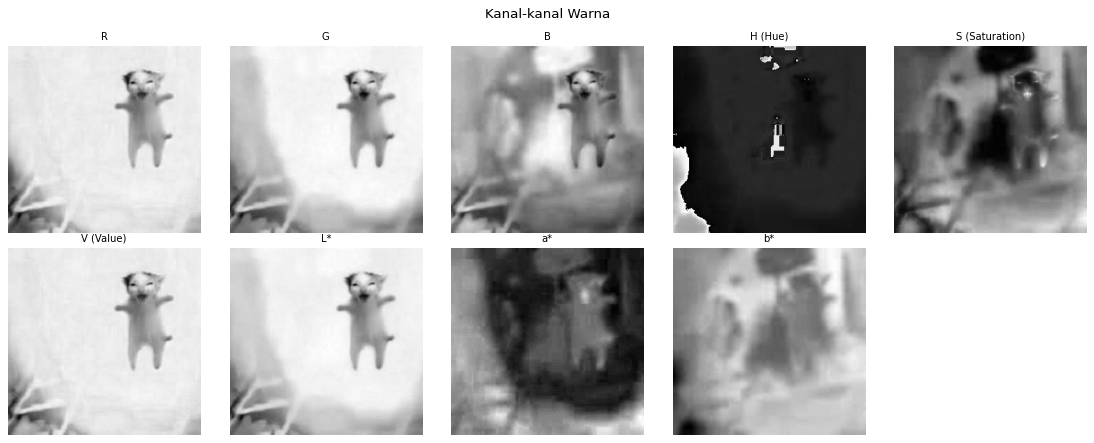

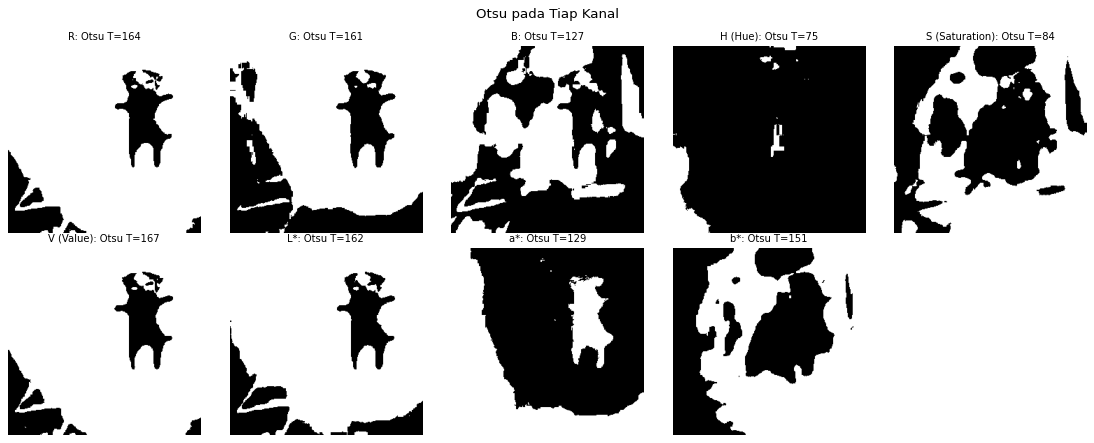

In [6]:
# A.4 Eksperimen: thresholding pada kanal warna lain
hsv = cv2.cvtColor(img_color, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(img_color, cv2.COLOR_BGR2LAB)
channels = {
    'R': img_rgb[:, :, 0], 'G': img_rgb[:, :, 1], 'B': img_rgb[:, :, 2],
    'H (Hue)': hsv[:, :, 0], 'S (Saturation)': hsv[:, :, 1], 'V (Value)': hsv[:, :, 2],
    'L*': lab[:, :, 0], 'a*': lab[:, :, 1], 'b*': lab[:, :, 2],
}
show_grid(list(channels.values()), list(channels.keys()), cols=5, size=2.8, suptitle='Kanal-kanal Warna')

ims, tts = [], []
for name, ch in channels.items():
    t, th = cv2.threshold(ch, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    ims.append(th)
    tts.append(f'{name}: Otsu T={t:.0f}')
show_grid(ims, tts, cols=5, size=2.8, suptitle='Otsu pada Tiap Kanal')

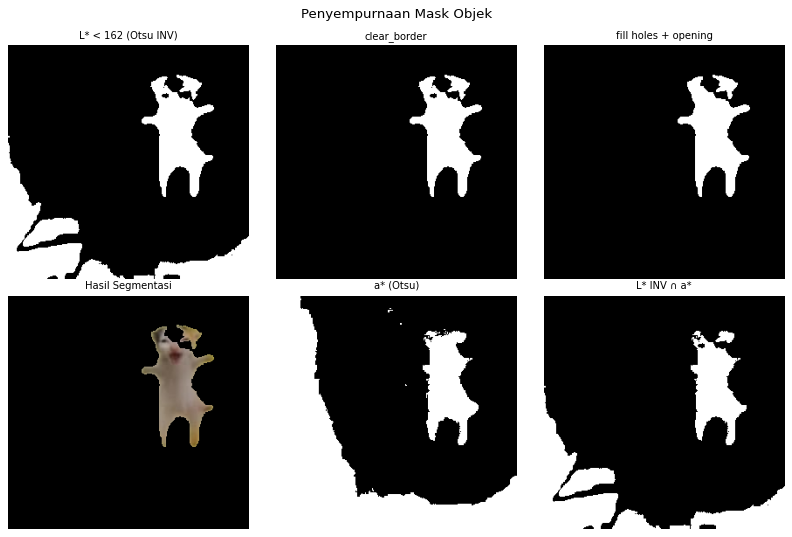

Persentase piksel kucing: 7.37%

In [7]:
# A.5 Eksperimen: menyempurnakan mask kucing
from skimage.segmentation import clear_border
from scipy.ndimage import binary_fill_holes

L = lab[:, :, 0]
t_L, mask_L = cv2.threshold(L, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
mask_nb = clear_border(mask_L > 0)
mask_fill = binary_fill_holes(mask_nb)
obj_mask = cv2.morphologyEx(mask_fill.astype(np.uint8) * 255, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8), iterations=1)

# Alternatif: irisan mask L* (gelap) dengan mask a* (kemerahan)
_, mask_a = cv2.threshold(lab[:, :, 1], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
mask_and = cv2.bitwise_and(mask_L, mask_a)

seg_obj = cv2.bitwise_and(img_rgb, img_rgb, mask=obj_mask)
show_grid([mask_L, mask_nb, obj_mask, seg_obj, mask_a, mask_and],
          [f'L* < {t_L:.0f} (Otsu INV)', 'clear_border', 'fill holes + opening', 'Hasil Segmentasi',
           'a* (Otsu)', 'L* INV ∩ a*'],
          cols=3, size=3.4, suptitle='Penyempurnaan Mask Objek')
print('Persentase piksel kucing: %.2f%%' % fg_ratio(obj_mask))

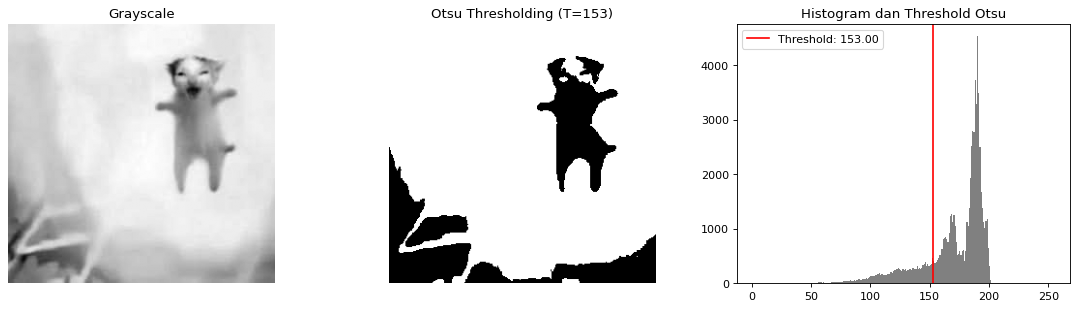

In [8]:
# B. Otsu's Method
# B.1 Implementasi dasar + histogram
T_otsu, otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1), plt.imshow(img, cmap='gray'), plt.title('Grayscale'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(otsu, cmap='gray'), plt.title(f'Otsu Thresholding (T={T_otsu:.0f})'), plt.axis('off')
plt.subplot(1, 3, 3)
plt.hist(img.ravel(), bins=256, range=[0, 256], color='gray')
plt.axvline(T_otsu, color='r', label=f'Threshold: {T_otsu:.2f}')
plt.title('Histogram dan Threshold Otsu')
plt.legend()
plt.tight_layout()
plt.show()

Threshold Otsu OpenCV : 153.0
Threshold Otsu manual : 153

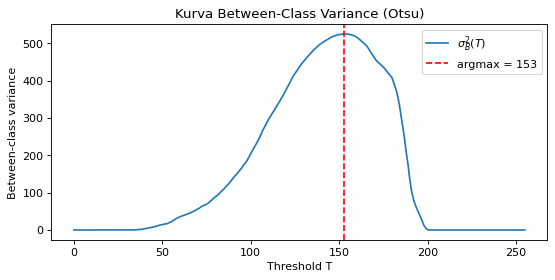

In [9]:
# B.2 Implementasi Otsu manual (verifikasi) dan kurva between-class variance
def otsu_manual(gray):
    hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    omega = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    mu_t = mu[-1]
    with np.errstate(divide='ignore', invalid='ignore'):
        sigma_b = (mu_t * omega - mu) ** 2 / (omega * (1 - omega))
    sigma_b = np.nan_to_num(sigma_b)
    return int(np.argmax(sigma_b)), sigma_b

T_manual, sigma_b = otsu_manual(img)
print('Threshold Otsu OpenCV :', T_otsu)
print('Threshold Otsu manual :', T_manual)

plt.figure(figsize=(8, 3.5))
plt.plot(sigma_b, label='$\\sigma_B^2(T)$')
plt.axvline(T_manual, color='r', ls='--', label=f'argmax = {T_manual}')
plt.xlabel('Threshold T'), plt.ylabel('Between-class variance')
plt.title('Kurva Between-Class Variance (Otsu)')
plt.legend()
plt.show()

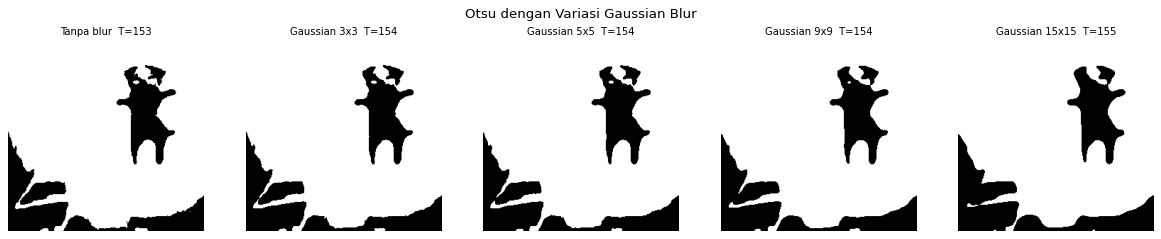

In [10]:
# B.3 Eksperimen: pengaruh Gaussian blur sebelum Otsu
ims, tts = [], []
for k in [0, 3, 5, 9, 15]:
    src = img if k == 0 else cv2.GaussianBlur(img, (k, k), 0)
    t, th = cv2.threshold(src, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    ims.append(th)
    tts.append(('Tanpa blur' if k == 0 else f'Gaussian {k}x{k}') + f'  T={t:.0f}')
show_grid(ims, tts, cols=5, size=3, suptitle='Otsu dengan Variasi Gaussian Blur')

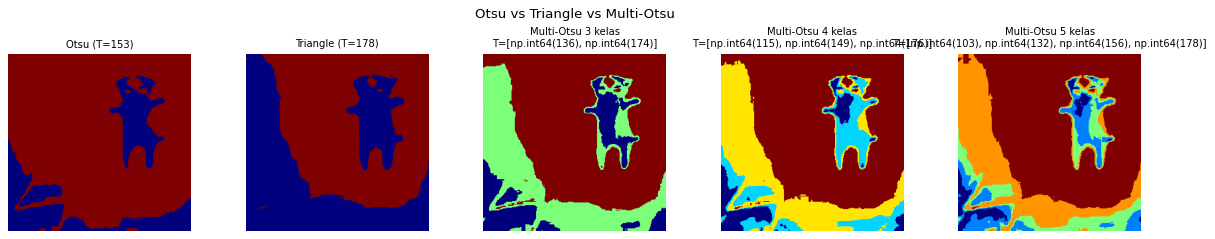

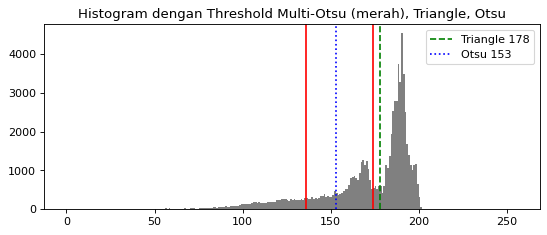

In [11]:
# B.4 Eksperimen: metode threshold otomatis lain (Triangle) dan Multi-Otsu
T_tri, tri = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_TRIANGLE)

ims, tts = [otsu, tri], [f'Otsu (T={T_otsu:.0f})', f'Triangle (T={T_tri:.0f})']
for n_cls in [3, 4, 5]:
    th_m = threshold_multiotsu(img, classes=n_cls)
    regions = np.digitize(img, bins=th_m)
    ims.append(regions)
    tts.append(f'Multi-Otsu {n_cls} kelas\nT={list(th_m)}')
show_grid(ims, tts, cols=5, size=3, cmap='jet', suptitle='Otsu vs Triangle vs Multi-Otsu')

th3 = threshold_multiotsu(img, classes=3)
plt.figure(figsize=(8, 3))
plt.hist(img.ravel(), bins=256, range=[0, 256], color='gray')
for t in th3:
    plt.axvline(t, color='r')
plt.axvline(T_tri, color='g', ls='--', label=f'Triangle {T_tri:.0f}')
plt.axvline(T_otsu, color='b', ls=':', label=f'Otsu {T_otsu:.0f}')
plt.title('Histogram dengan Threshold Multi-Otsu (merah), Triangle, Otsu')
plt.legend()
plt.show()

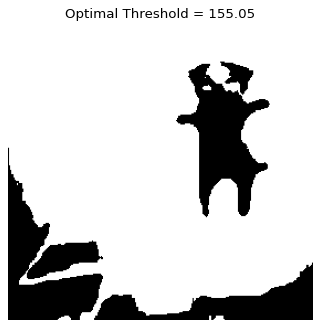

In [12]:
# C. Optimal Thresholding (Iteratif)
# C.1 Implementasi sesuai template
def optimal_threshold(img):
    T = img.mean()
    while True:
        G1 = img[img > T]
        G2 = img[img <= T]
        new_T = (G1.mean() + G2.mean()) / 2
        if abs(T - new_T) < 1:
            break
        T = new_T
    return T

T = optimal_threshold(img)
ret, opt_thresh = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)
plt.imshow(opt_thresh, cmap='gray')
plt.title(f'Optimal Threshold = {T:.2f}')
plt.axis('off')
plt.show()

        T0 |    eps | iterasi |  T akhir
------------------------------------------
      mean |    1.0 |       6 |  154.559
      mean |    0.1 |       8 |  154.106
      mean |  0.001 |       8 |  154.106
        20 |    1.0 |       0 |   20.000
        20 |    0.1 |       0 |   20.000
        20 |  0.001 |       0 |   20.000
        40 |    1.0 |       7 |  153.166
        40 |    0.1 |       9 |  153.659
        40 |  0.001 |       9 |  153.659
       100 |    1.0 |       6 |  153.166
       100 |    0.1 |       8 |  153.659
       100 |  0.001 |       8 |  153.659
       195 |    1.0 |       8 |  154.559
       195 |    0.1 |      10 |  154.106
       195 |  0.001 |      10 |  154.106
       230 |    1.0 |       0 |  230.000
       230 |    0.1 |       0 |  230.000
       230 |  0.001 |       0 |  230.000

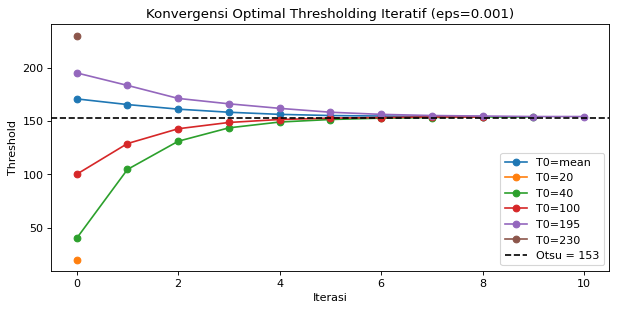

In [13]:
# C.2 Eksperimen: variasi threshold awal dan toleransi konvergensi
def optimal_threshold_ex(img, T0=None, eps=1.0, max_iter=100):
    T = img.mean() if T0 is None else float(T0)
    history = [T]
    for _ in range(max_iter):
        G1 = img[img > T]
        G2 = img[img <= T]
        if len(G1) == 0 or len(G2) == 0:
            break
        new_T = (G1.mean() + G2.mean()) / 2
        history.append(new_T)
        if abs(T - new_T) < eps:
            T = new_T
            break
        T = new_T
    return T, history

print(f"{'T0':>10} | {'eps':>6} | {'iterasi':>7} | {'T akhir':>8}")
print('-' * 42)
plt.figure(figsize=(9, 4))
for T0 in [None, 20, 40, 100, 195, 230]:
    for eps in [1.0, 0.1, 0.001]:
        T_f, hist_T = optimal_threshold_ex(img, T0, eps)
        label = 'mean' if T0 is None else T0
        print(f"{str(label):>10} | {eps:>6} | {len(hist_T)-1:>7} | {T_f:>8.3f}")
        if eps == 0.001:
            plt.plot(hist_T, marker='o', label=f'T0={label}')
plt.axhline(T_otsu, color='k', ls='--', label=f'Otsu = {T_otsu:.0f}')
plt.xlabel('Iterasi'), plt.ylabel('Threshold')
plt.title('Konvergensi Optimal Thresholding Iteratif (eps=0.001)')
plt.legend()
plt.show()

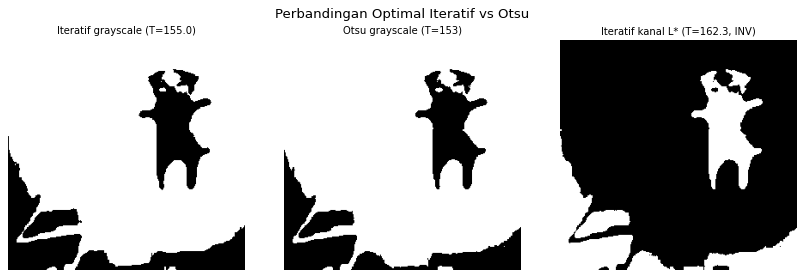

In [14]:
T_opt_L, _ = optimal_threshold_ex(L, eps=0.01)
_, opt_L = cv2.threshold(L, T_opt_L, 255, cv2.THRESH_BINARY_INV)
show_grid([opt_thresh, otsu, opt_L],
          [f'Iteratif grayscale (T={T:.1f})', f'Otsu grayscale (T={T_otsu:.0f})', f'Iteratif kanal L* (T={T_opt_L:.1f}, INV)'],
          cols=3, size=3.5, suptitle='Perbandingan Optimal Iteratif vs Otsu')

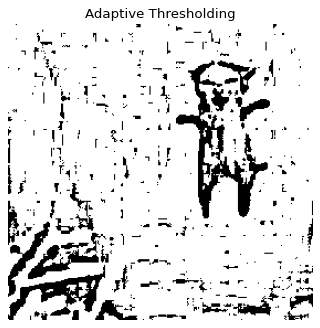

In [15]:
# D. Adaptive Thresholding
# D.1 Implementasi dasar (Mean, block 11, C=2)
adaptive = cv2.adaptiveThreshold(img, 255,
                                 cv2.ADAPTIVE_THRESH_MEAN_C,
                                 cv2.THRESH_BINARY, 11, 2)
plt.imshow(adaptive, cmap='gray')
plt.title('Adaptive Thresholding')
plt.axis('off')
plt.show()

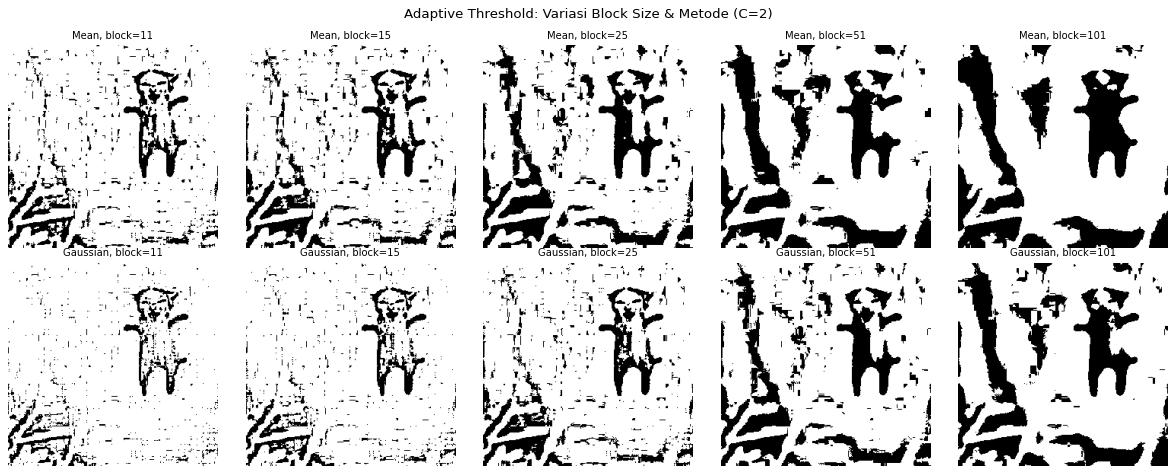

In [16]:
# D.2 Eksperimen ukuran blok (Mean vs Gaussian)
blocks = [11, 15, 25, 51, 101]
ims, tts = [], []
for method, mname in [(cv2.ADAPTIVE_THRESH_MEAN_C, 'Mean'), (cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 'Gaussian')]:
    for block_size in blocks:
        ad = cv2.adaptiveThreshold(img, 255, method, cv2.THRESH_BINARY, block_size, 2)
        ims.append(ad)
        tts.append(f'{mname}, block={block_size}')
show_grid(ims, tts, cols=5, size=3, suptitle='Adaptive Threshold: Variasi Block Size & Metode (C=2)')

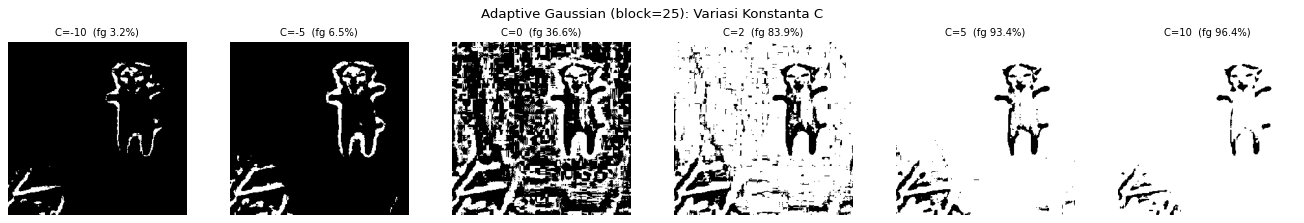

In [17]:
# D.3 Eksperimen konstanta C
ims, tts = [], []
for Cval in [-10, -5, 0, 2, 5, 10]:
    ad = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 25, Cval)
    ims.append(ad)
    tts.append(f'C={Cval}  (fg {fg_ratio(ad):.1f}%)')
show_grid(ims, tts, cols=6, size=2.8, suptitle='Adaptive Gaussian (block=25): Variasi Konstanta C')

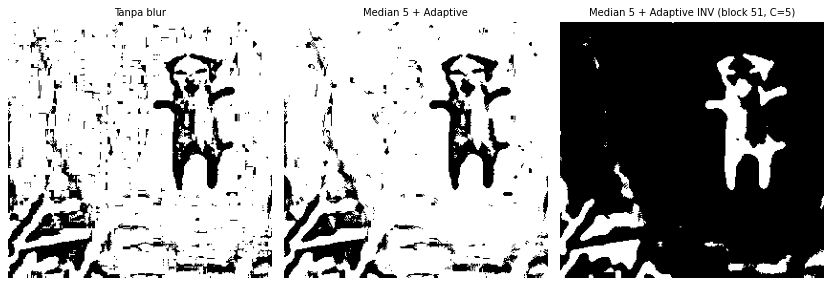

In [18]:
# D.4 Eksperimen: adaptive threshold setelah smoothing
blur_m = cv2.medianBlur(img, 5)
ims = [cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 25, 2),
       cv2.adaptiveThreshold(blur_m, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 25, 2),
       cv2.adaptiveThreshold(blur_m, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 51, 5)]
show_grid(ims, ['Tanpa blur', 'Median 5 + Adaptive', 'Median 5 + Adaptive INV (block 51, C=5)'],
          cols=3, size=3.5)

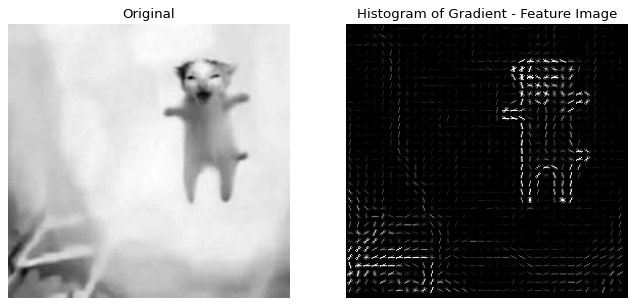

Panjang vektor fitur HoG: 38016

In [19]:
# E. Histogram of Oriented Gradient (HoG)
# E.1 Implementasi dasar
fd, hog_image = hog(img, orientations=9, pixels_per_cell=(8, 8),
                    cells_per_block=(2, 2), visualize=True)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(122), plt.imshow(exposure.rescale_intensity(hog_image, in_range=(0, 10)), cmap='gray')
plt.title('Histogram of Gradient - Feature Image'), plt.axis('off')
plt.show()
print('Panjang vektor fitur HoG:', fd.shape[0])

orient |      ppc |    cpb | len fitur | waktu (ms)
     9 |   (8, 8) | (2, 2) |     38016 |       65.2
     8 | (16, 16) | (1, 1) |      2176 |       15.1
     4 |   (8, 8) | (2, 2) |     16896 |       31.6
    18 |   (8, 8) | (2, 2) |     76032 |      106.3
     9 |   (4, 4) | (2, 2) |    161568 |      225.4
     9 | (16, 16) | (2, 2) |      8640 |       17.2
     9 | (32, 32) | (2, 2) |      1764 |        7.1
     9 |   (8, 8) | (3, 3) |     80352 |       65.2

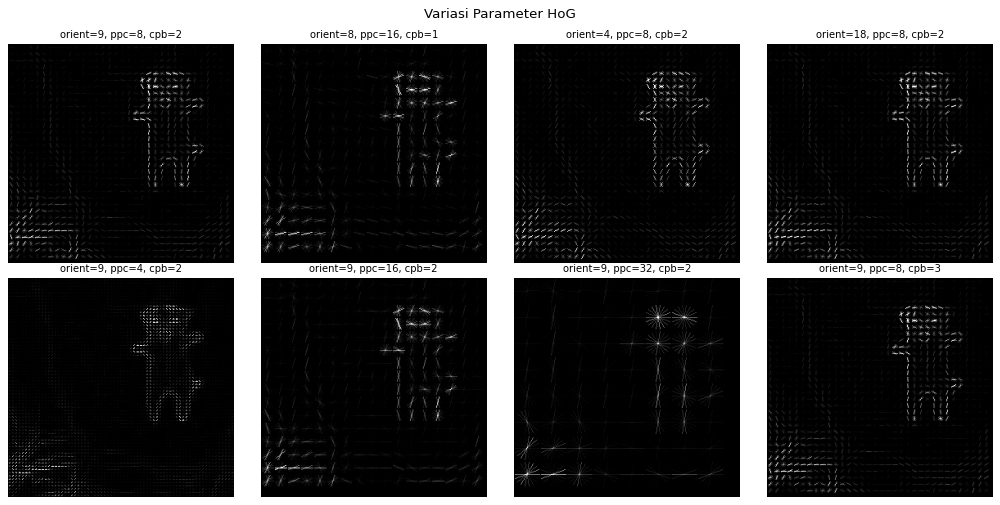

In [20]:
# E.2 Eksperimen variasi `orientations`, `pixels_per_cell`, `cells_per_block`
configs = [
    (9, (8, 8), (2, 2)),
    (8, (16, 16), (1, 1)),
    (4, (8, 8), (2, 2)),
    (18, (8, 8), (2, 2)),
    (9, (4, 4), (2, 2)),
    (9, (16, 16), (2, 2)),
    (9, (32, 32), (2, 2)),
    (9, (8, 8), (3, 3)),
]
ims, tts = [], []
print(f"{'orient':>6} | {'ppc':>8} | {'cpb':>6} | {'len fitur':>9} | {'waktu (ms)':>10}")
for o, ppc, cpb in configs:
    t0 = time.time()
    fd_i, hog_i = hog(img, orientations=o, pixels_per_cell=ppc, cells_per_block=cpb, visualize=True)
    dt = (time.time() - t0) * 1000
    print(f"{o:>6} | {str(ppc):>8} | {str(cpb):>6} | {fd_i.shape[0]:>9} | {dt:>10.1f}")
    ims.append(exposure.rescale_intensity(hog_i, in_range=(0, hog_i.max() / 2)))
    tts.append(f'orient={o}, ppc={ppc[0]}, cpb={cpb[0]}')
show_grid(ims, tts, cols=4, size=3.2, suptitle='Variasi Parameter HoG')

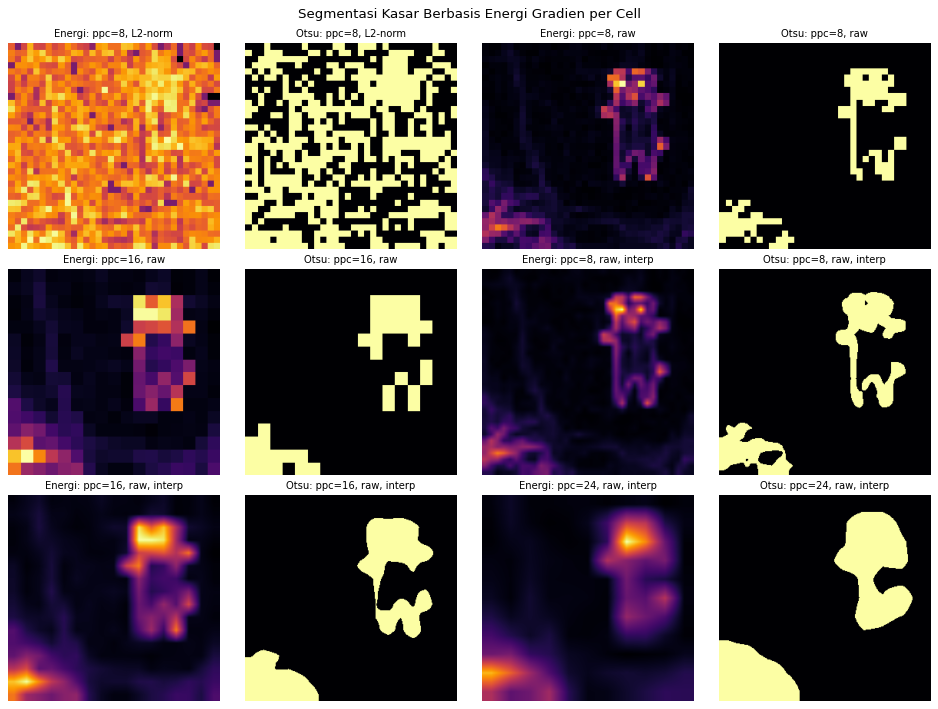

In [21]:
# E.3 Eksperimen: segmentasi kasar berbasis magnitudo HoG
def hog_energy_mask(gray, ppc, normalize_block, smooth):
    # cells_per_block=(1,1) + normalisasi L2 membuat setiap cell bernorma ~1 (energi rata),
    # sehingga dibandingkan juga versi tanpa normalisasi (magnitudo gradien mentah per cell).
    if normalize_block:
        fd_c = hog(gray, orientations=9, pixels_per_cell=(ppc, ppc), cells_per_block=(1, 1), feature_vector=False)
        energy = fd_c.reshape(fd_c.shape[0], fd_c.shape[1], -1).sum(axis=-1)
    else:
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1)
        mag = cv2.magnitude(gx, gy)
        h, w = gray.shape[0] // ppc, gray.shape[1] // ppc
        energy = mag[:h * ppc, :w * ppc].reshape(h, ppc, w, ppc).sum(axis=(1, 3))
    up = cv2.resize(energy.astype(np.float32), (gray.shape[1], gray.shape[0]),
                    interpolation=cv2.INTER_LINEAR if smooth else cv2.INTER_NEAREST)
    up8 = cv2.normalize(up, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, m = cv2.threshold(up8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return up8, m

ims, tts = [], []
for ppc, norm, smooth in [(8, True, False), (8, False, False), (16, False, False), (8, False, True), (16, False, True), (24, False, True)]:
    e, m = hog_energy_mask(img, ppc, norm, smooth)
    ims += [e, m]
    tag = f"ppc={ppc}, {'L2-norm' if norm else 'raw'}{', interp' if smooth else ''}"
    tts += [f'Energi: {tag}', f'Otsu: {tag}']
show_grid(ims, tts, cols=4, size=3, cmap='inferno', suptitle='Segmentasi Kasar Berbasis Energi Gradien per Cell')

_, hog_mask = hog_energy_mask(img, 16, False, True)

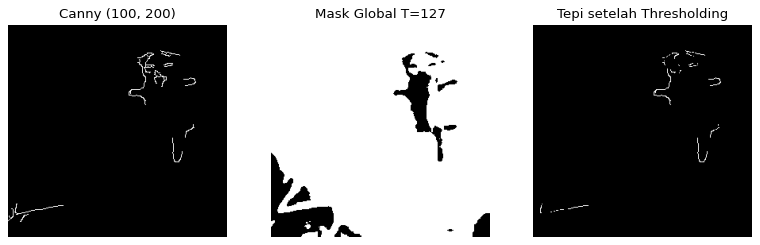

In [22]:
# F. Integrasi dengan Penyambungan Tepi
# F.1 Implementasi template (Canny ∩ mask threshold)
edges = cv2.Canny(img, 100, 200)
masked = cv2.bitwise_and(edges, edges, mask=thresh)
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(edges, cmap='gray'), plt.title('Canny (100, 200)'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(thresh, cmap='gray'), plt.title('Mask Global T=127'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(masked, cmap='gray'), plt.title('Tepi setelah Thresholding'), plt.axis('off')
plt.show()

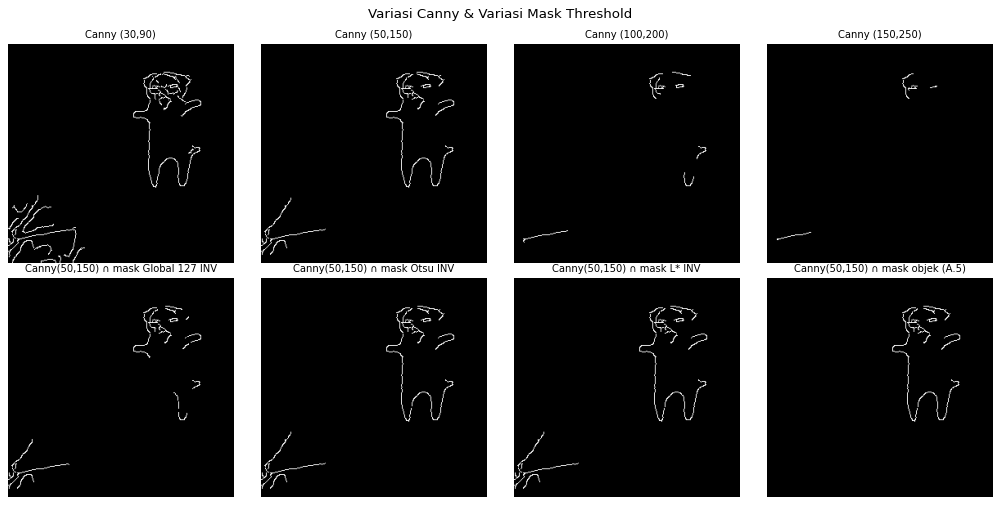

In [23]:
# F.2 Eksperimen: variasi threshold Canny dan variasi mask
canny_params = [(30, 90), (50, 150), (100, 200), (150, 250)]
blur5 = cv2.GaussianBlur(img, (5, 5), 0)
ims, tts = [], []
for lo, hi in canny_params:
    e = cv2.Canny(blur5, lo, hi)
    ims.append(e)
    tts.append(f'Canny ({lo},{hi})')
for mask, mname in [(255 - thresh, 'Global 127 INV'), (255 - otsu, 'Otsu INV'), (mask_L, 'L* INV'), (obj_mask, 'objek (A.5)')]:
    e = cv2.Canny(blur5, 50, 150)
    mask_d = cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=2)
    ims.append(cv2.bitwise_and(e, e, mask=mask_d))
    tts.append(f'Canny(50,150) ∩ mask {mname}')
show_grid(ims, tts, cols=4, size=3.2, suptitle='Variasi Canny & Variasi Mask Threshold')

Jumlah kontur: 2 | luas kontur terbesar: 4845.0 | bbox: (153, 36, 83, 138)

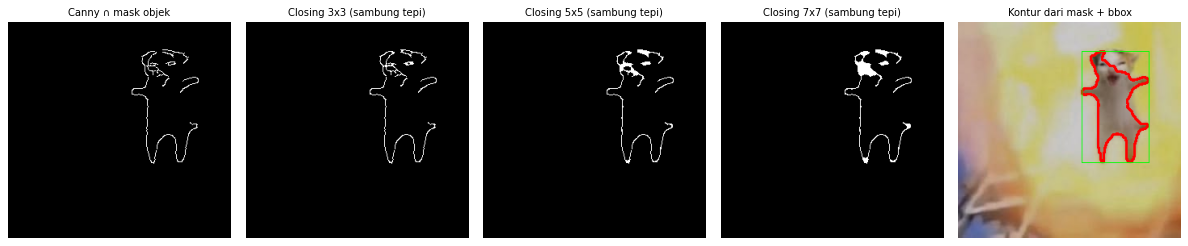

In [24]:
# F.3 Eksperimen: penyambungan tepi menjadi kontur objek
contours, _ = cv2.findContours(obj_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
largest = max(contours, key=cv2.contourArea)
vis = img_rgb.copy()
cv2.drawContours(vis, [largest], -1, (255, 0, 0), 2)
x, y, w, h = cv2.boundingRect(largest)
cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 1)
print('Jumlah kontur:', len(contours), '| luas kontur terbesar:', cv2.contourArea(largest), '| bbox:', (x, y, w, h))

e = cv2.Canny(blur5, 50, 150)
e_obj = cv2.bitwise_and(e, e, mask=cv2.dilate(obj_mask, np.ones((3, 3), np.uint8), iterations=2))
ims, tts = [e_obj], ['Canny ∩ mask objek']
for k in [3, 5, 7]:
    ims.append(cv2.morphologyEx(e_obj, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))))
    tts.append(f'Closing {k}x{k} (sambung tepi)')
ims.append(vis); tts.append('Kontur dari mask + bbox')
show_grid(ims, tts, cols=5, size=3)

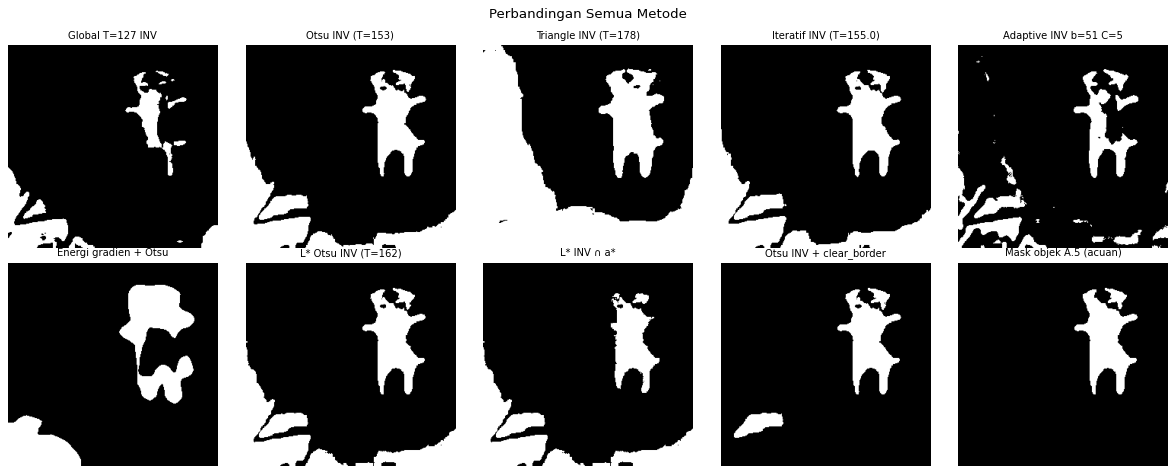

Metode                     | fg (%) | IoU vs acuan
----------------------------------------------------
Global T=127 INV           |    9.6 |        0.257
Otsu INV (T=153)           |   20.2 |        0.358
Triangle INV (T=178)       |   45.0 |        0.164
Iteratif INV (T=155.0)     |   21.3 |        0.344
Adaptive INV b=51 C=5      |   11.9 |        0.378
Energi gradien + Otsu      |   16.0 |        0.231
L* Otsu INV (T=162)        |   20.3 |        0.360
L* INV ∩ a*                |   19.0 |        0.295
Otsu INV + clear_border    |    8.9 |        0.804
Mask objek A.5 (acuan)     |    7.4 |        1.000

In [25]:
# G. Ringkasan Perbandingan Metode
results = {
    'Global T=127 INV': 255 - thresh,
    f'Otsu INV (T={T_otsu:.0f})': 255 - otsu,
    f'Triangle INV (T={T_tri:.0f})': 255 - tri,
    f'Iteratif INV (T={T:.1f})': 255 - opt_thresh,
    'Adaptive INV b=51 C=5': cv2.adaptiveThreshold(blur_m, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 51, 5),
    'Energi gradien + Otsu': hog_mask,
    f'L* Otsu INV (T={t_L:.0f})': mask_L,
    'L* INV ∩ a*': mask_and,
    'Otsu INV + clear_border': clear_border(otsu == 0).astype(np.uint8) * 255,
    'Mask objek A.5 (acuan)': obj_mask,
}
show_grid(list(results.values()), list(results.keys()), cols=5, size=3, suptitle='Perbandingan Semua Metode')

ref = obj_mask > 0
print(f"{'Metode':<26} | {'fg (%)':>6} | {'IoU vs acuan':>12}")
print('-' * 52)
for name, m in results.items():
    mb = m > 0
    iou = np.logical_and(mb, ref).sum() / np.logical_or(mb, ref).sum()
    print(f"{name:<26} | {fg_ratio(m):>6.1f} | {iou:>12.3f}")